# AstroGuard Exploratory Analysis

This notebook follows the AstroGuard Data Analysis and Statistics assignment. It reads only `data/processed/astronaut_health.csv`, checks data quality, summarizes measurements, compares each crew member with a days 1–14 personal baseline, calculates the four requested relationships, and creates the ten charts and CSV outputs.

**Important:** the dataset is simulated. The results are not clinical evidence. Ground-truth label files are not used.

In [1]:
from pathlib import Path
import sys
import pandas as pd

# Find the project folder from this notebook's location, not from a user-specific path.
cwd = Path.cwd().resolve()
possible_roots = [cwd, *cwd.parents]
PROJECT_ROOT = next(
    (p for p in possible_roots if (p / "data" / "processed" / "astronaut_health.csv").exists()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/processed/astronaut_health.csv. "
        "Open the AstroGuard_Submission folder in VS Code and run this notebook there."
    )

sys.path.insert(0, str(PROJECT_ROOT))
from src.exploratory_analysis import load_data, NUMERIC_COLUMNS, run_analysis

data = load_data()
print("Dataset shape:", data.shape)
print("Crew members:", data["crew_id"].nunique())
print("Mission-day range:", data["mission_day"].min(), "to", data["mission_day"].max())
print("Duplicate rows:", data.duplicated().sum())

Dataset shape: (3600, 11)
Crew members: 20
Mission-day range: 1 to 180
Duplicate rows: 0


## 1. Inspect data quality

Missing values are reported rather than automatically deleted. Unusual measurements may be useful signals and should be reviewed, not removed without a reason.

In [2]:
quality = pd.DataFrame({
    "dtype": data.dtypes.astype(str),
    "missing_count": data.isna().sum(),
    "missing_percent": (data.isna().mean() * 100).round(3),
    "unique_values": data.nunique(dropna=True)
})
print("Column quality checks")
display(quality)
print("Summary statistics for numeric measurements")
display(data[NUMERIC_COLUMNS].describe().T.round(2))
print("Crew member mission-day coverage")
coverage = data.groupby("crew_id").agg(
    first_day=("mission_day", "min"),
    last_day=("mission_day", "max"),
    unique_days=("mission_day", "nunique"),
    records=("mission_day", "count")
)
display(coverage)
print("Total missing cells:", int(data.isna().sum().sum()))
print("Duplicate rows:", int(data.duplicated().sum()))


Column quality checks


,dtype,missing_count,missing_percent,unique_values
crew_id,str,0,0.000,20
mission_day,int64,0,0.000,180
timestamp,datetime64[us],0,0.000,180
sleep_hours,float64,1,0.028,52
sleep_quality,float64,1,0.028,9
resting_heart_rate,float64,3,0.083,31
exercise_minutes,int64,0,0.000,75
fatigue_score,float64,1,0.028,9
stress_score,int64,0,0.000,9
reaction_time_ms,float64,3,0.083,216


Summary statistics for numeric measurements


,count,mean,std,min,25%,50%,75%,max
sleep_hours,3599.0,7.17,0.67,3.6,6.8,7.2,7.6,9.0
sleep_quality,3599.0,7.09,1.28,2.0,6.0,7.0,8.0,10.0
resting_heart_rate,3597.0,67.32,5.19,51.0,64.0,67.0,71.0,82.0
exercise_minutes,3600.0,57.66,11.85,14.0,50.0,58.0,66.0,96.0
fatigue_score,3599.0,3.83,1.37,1.0,3.0,4.0,5.0,9.0
stress_score,3600.0,3.27,1.44,1.0,2.0,3.0,4.0,9.0
reaction_time_ms,3597.0,468.86,40.87,356.0,437.0,464.0,499.0,640.0
workload_hours,3600.0,8.56,1.19,5.0,7.7,8.6,9.3,13.6


Crew member mission-day coverage


,first_day,last_day,unique_days,records
crew_id,,,,
Crew-01,1,180,180,180
Crew-02,1,180,180,180
Crew-03,1,180,180,180
Crew-04,1,180,180,180
Crew-05,1,180,180,180
Crew-06,1,180,180,180
Crew-07,1,180,180,180
Crew-08,1,180,180,180
Crew-09,1,180,180,180


Total missing cells: 9
Duplicate rows: 0


## 2. Relationship checks

Pearson correlation describes association. It does not prove cause and effect.

In [3]:
key_pairs = [
    ("sleep_hours", "fatigue_score"),
    ("workload_hours", "stress_score"),
    ("fatigue_score", "reaction_time_ms"),
    ("stress_score", "resting_heart_rate"),
]
correlation_rows = []
for first, second in key_pairs:
    paired = data[[first, second]].dropna()
    correlation_rows.append({
        "variable_1": first,
        "variable_2": second,
        "pearson_r": paired[first].corr(paired[second]),
        "paired_records": len(paired)
    })
display(pd.DataFrame(correlation_rows).round(3))


,variable_1,variable_2,pearson_r,paired_records
0,sleep_hours,fatigue_score,-0.122,3598
1,workload_hours,stress_score,0.498,3600
2,fatigue_score,reaction_time_ms,0.441,3596
3,stress_score,resting_heart_rate,0.246,3597


## 3. Generate and display all deliverables

The next cell runs the reusable Python analysis. It writes all ten PNG charts, CSV result tables, and updates `docs/DATA_ANALYSIS.md`. The following cell displays every saved chart inside this notebook. It is safe to rerun.


In [4]:
results = run_analysis()
print("\nAnalysis complete. Check assets/analysis_charts, assets/analysis_results, and docs.")

ASTROGUARD EXPLORATORY ANALYSIS
Dataset: data\processed\astronaut_health.csv
Shape: 3600 rows x 11 columns
Crew members: 20
Mission days: 1 to 180
Duplicate rows: 0

Missing values by column:
crew_id               0
mission_day           0
timestamp             0
sleep_hours           1
sleep_quality         1
resting_heart_rate    3
exercise_minutes      0
fatigue_score         1
stress_score          0
reaction_time_ms      3
workload_hours        0

Numerical summary:
       sleep_hours  sleep_quality  resting_heart_rate  exercise_minutes  fatigue_score  stress_score  reaction_time_ms  workload_hours
count      3599.00        3599.00             3597.00           3600.00        3599.00       3600.00           3597.00         3600.00
mean          7.17           7.09               67.32             57.66           3.83          3.27            468.86            8.56
std           0.67           1.28                5.19             11.85           1.37          1.44             40.87 

Displaying 10 saved charts:
correlation_heatmap.png


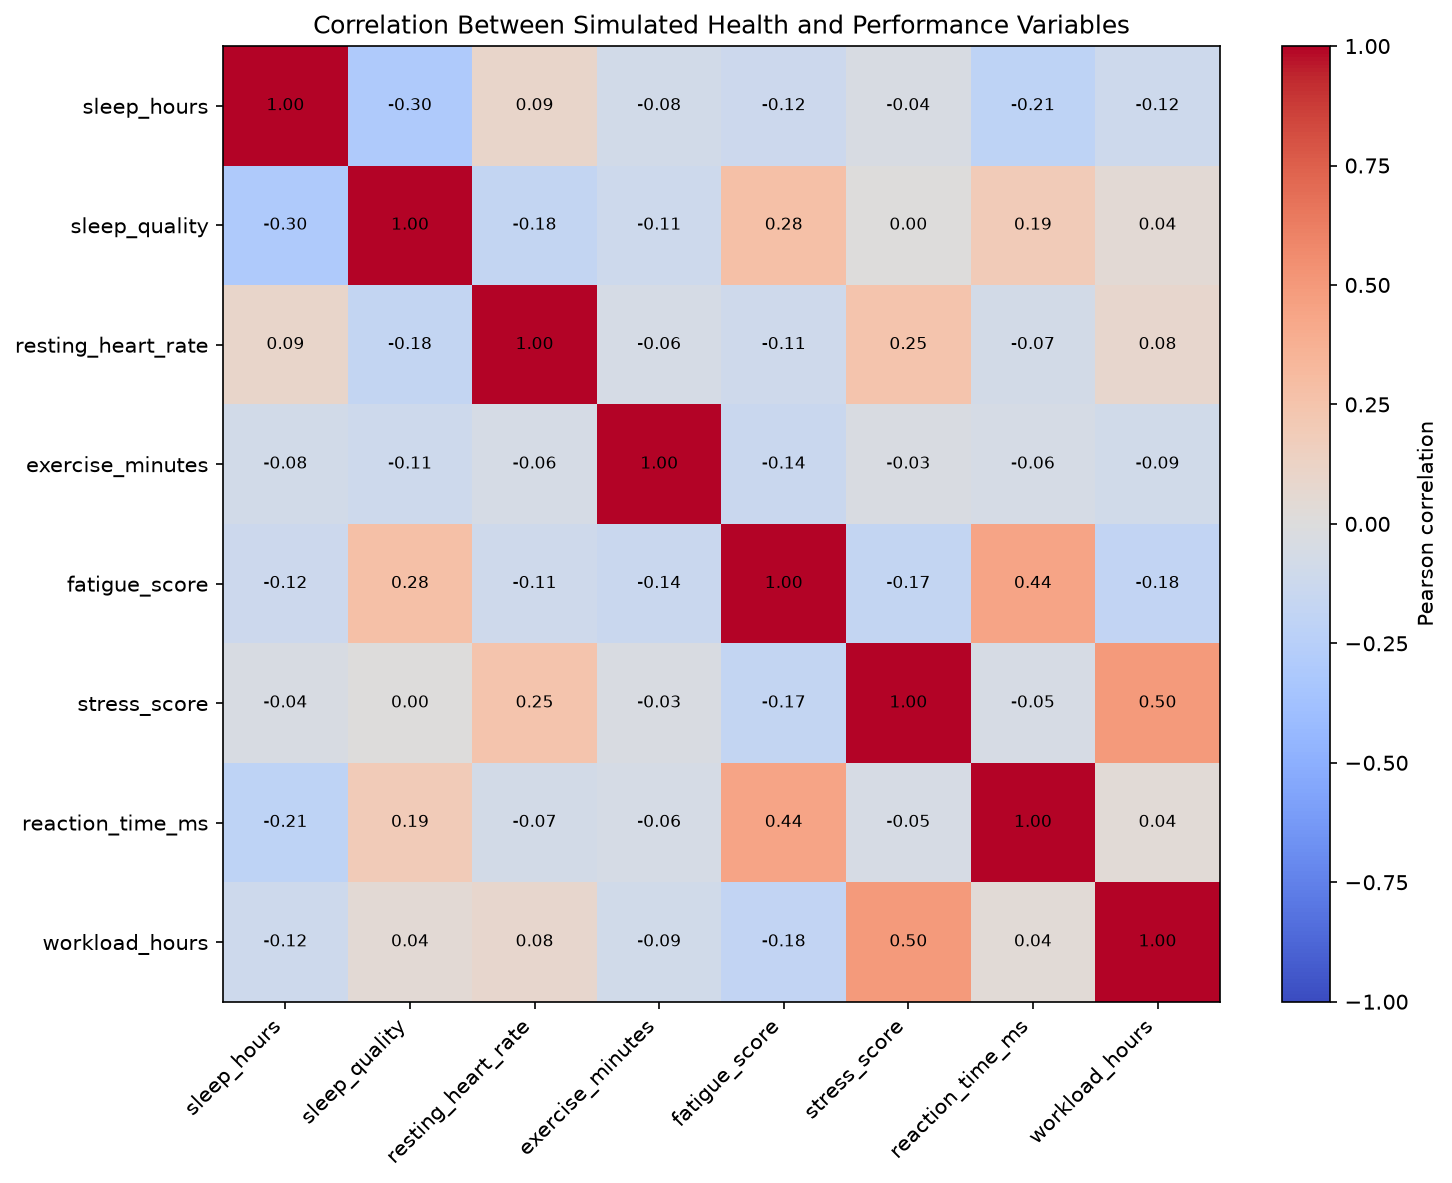

fatigue_crew01.png


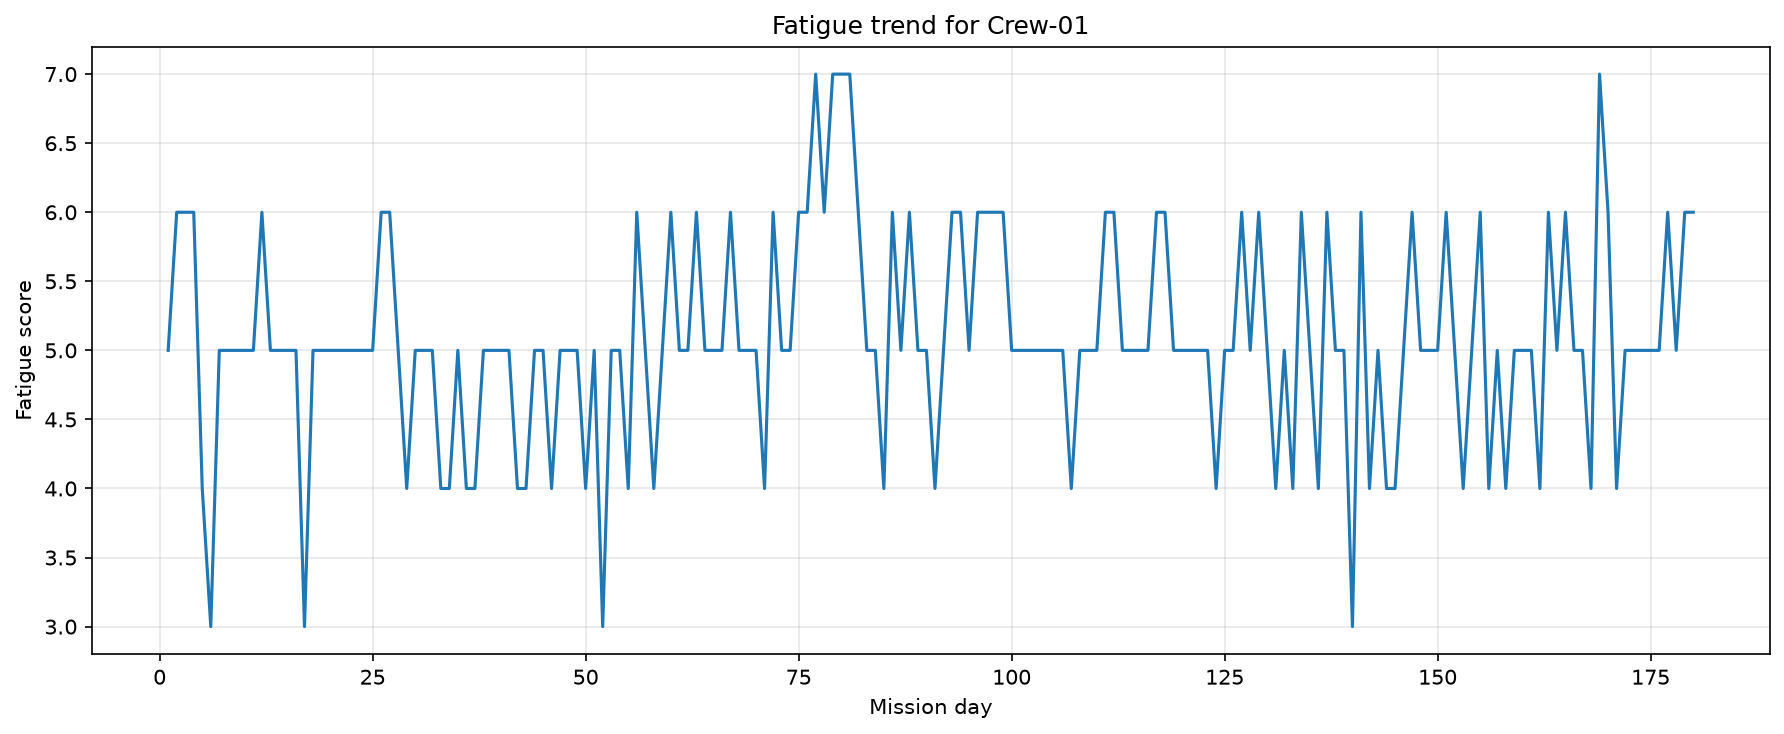

fatigue_score_all_crew_daily_average.png


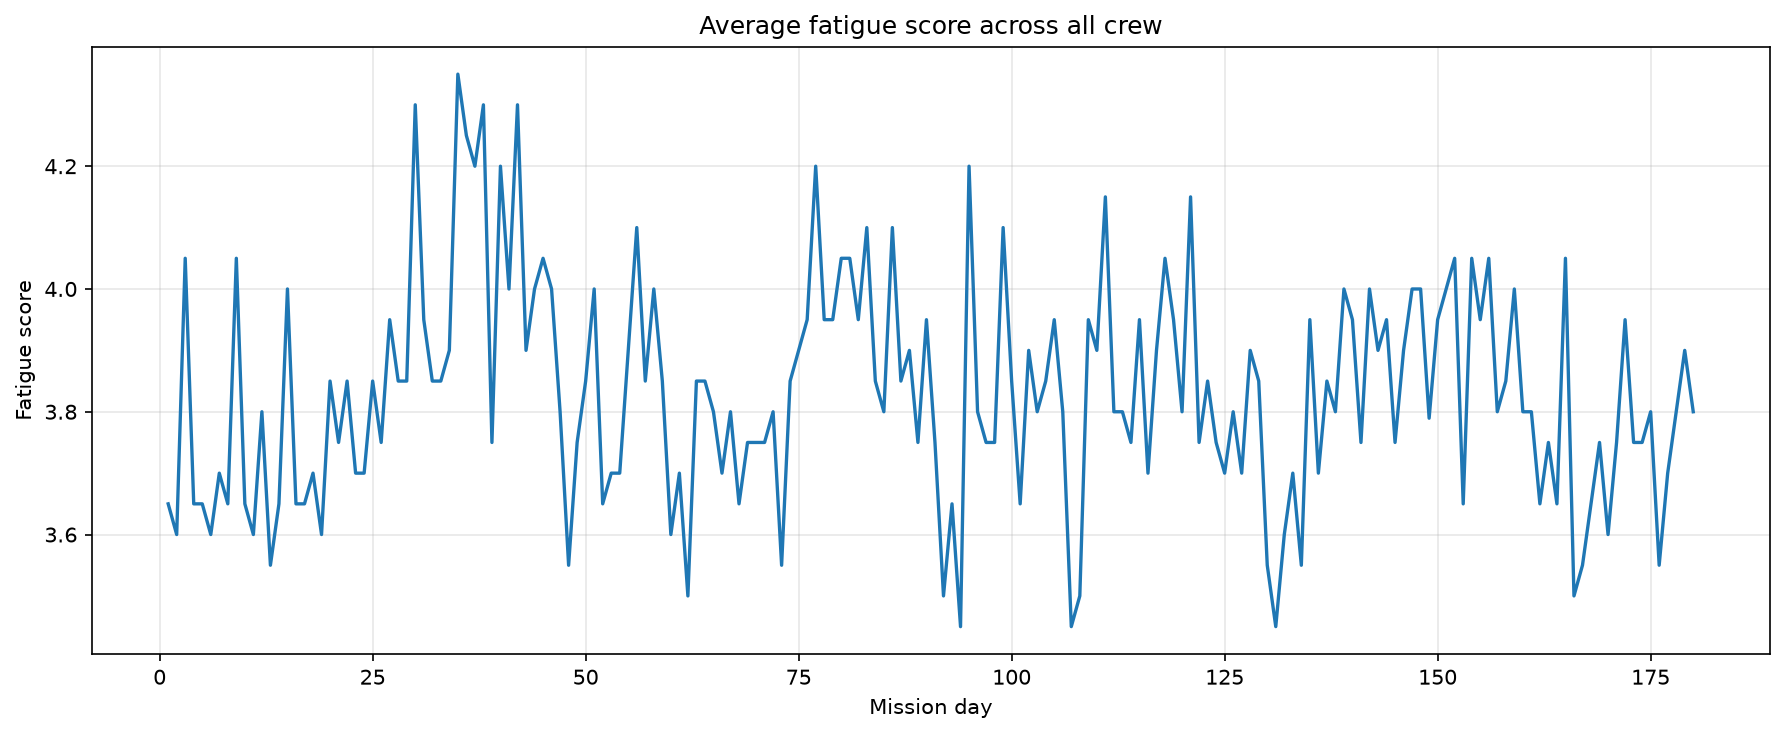

reaction_time_crew01.png


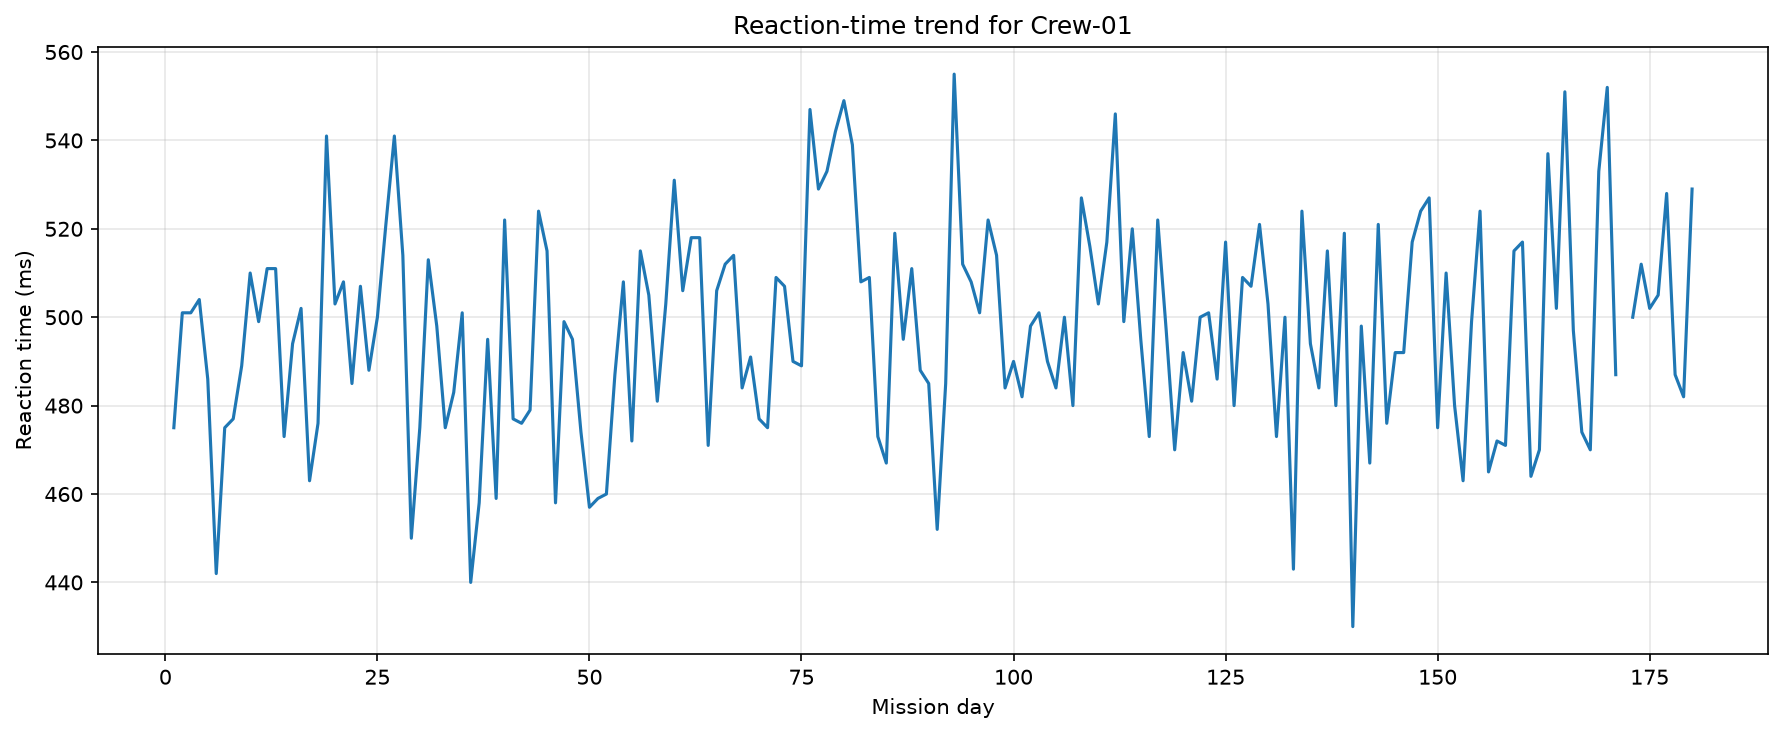

reaction_time_ms_all_crew_daily_average.png


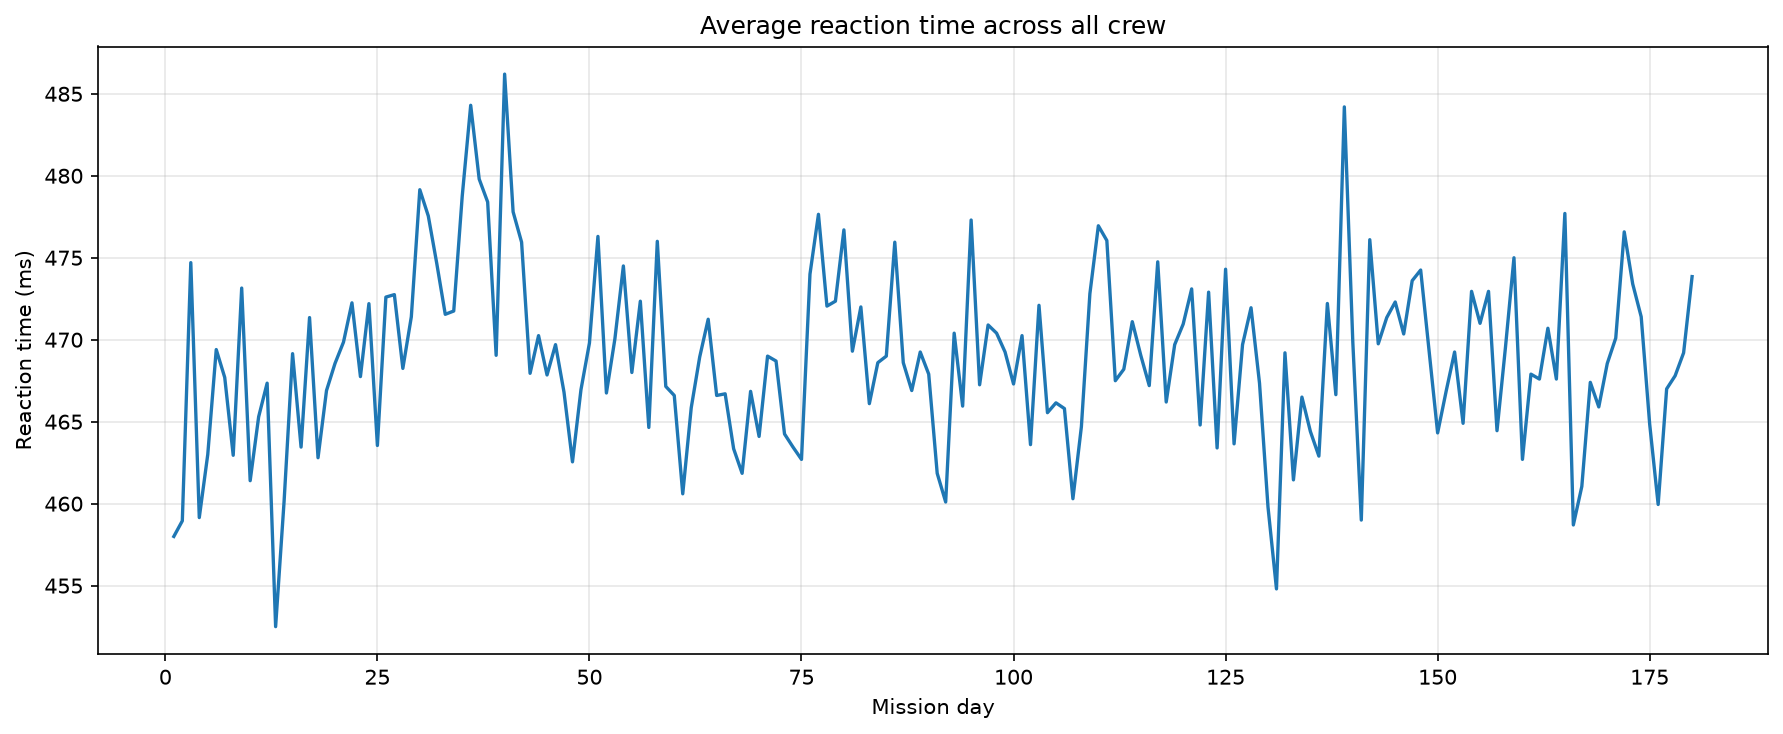

sleep_crew01.png


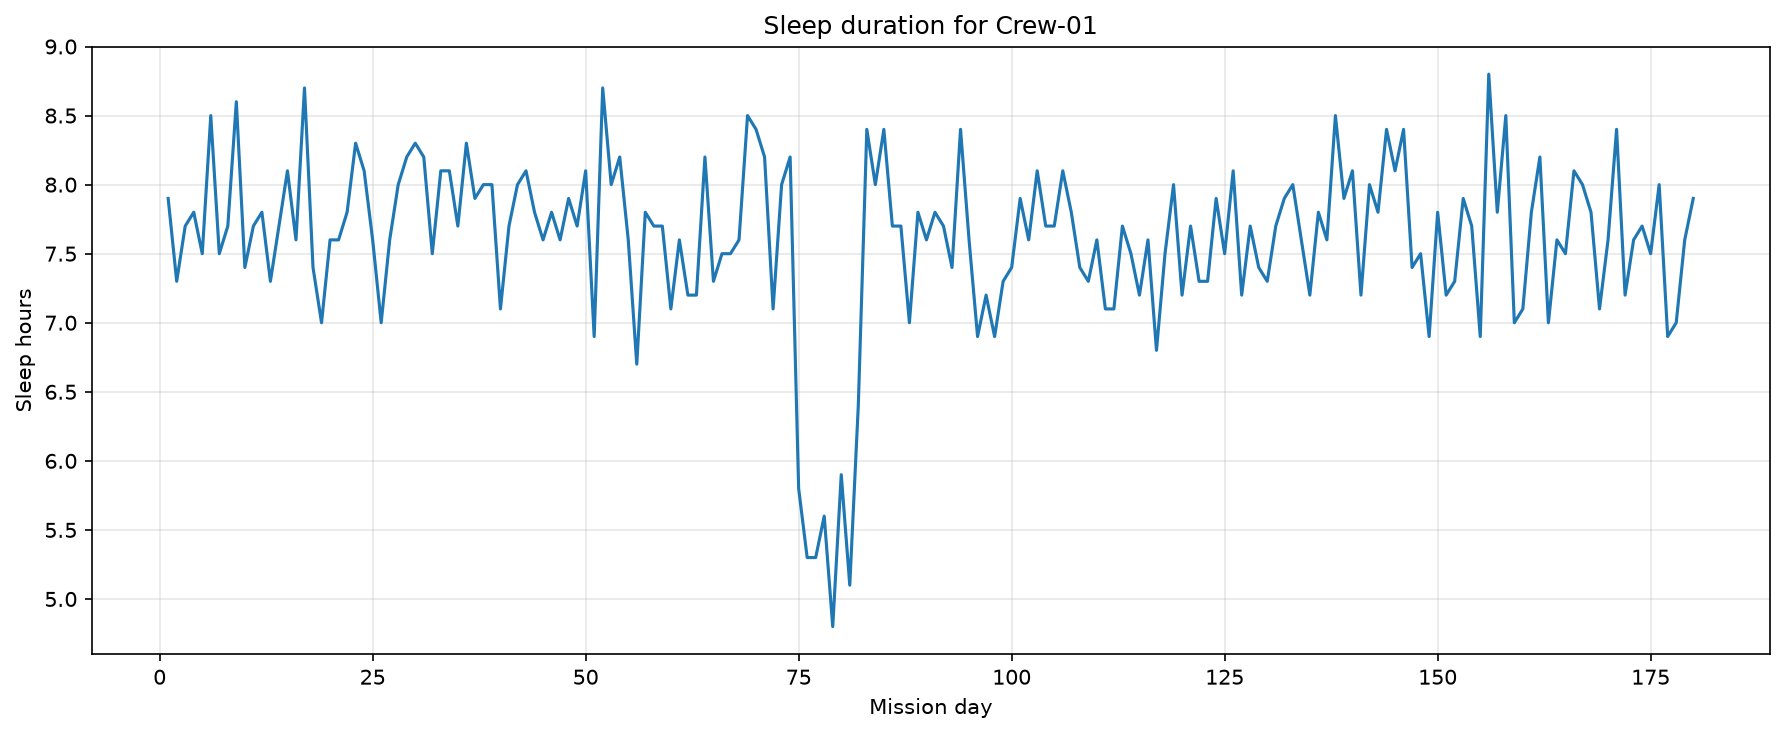

sleep_hours_all_crew_daily_average.png


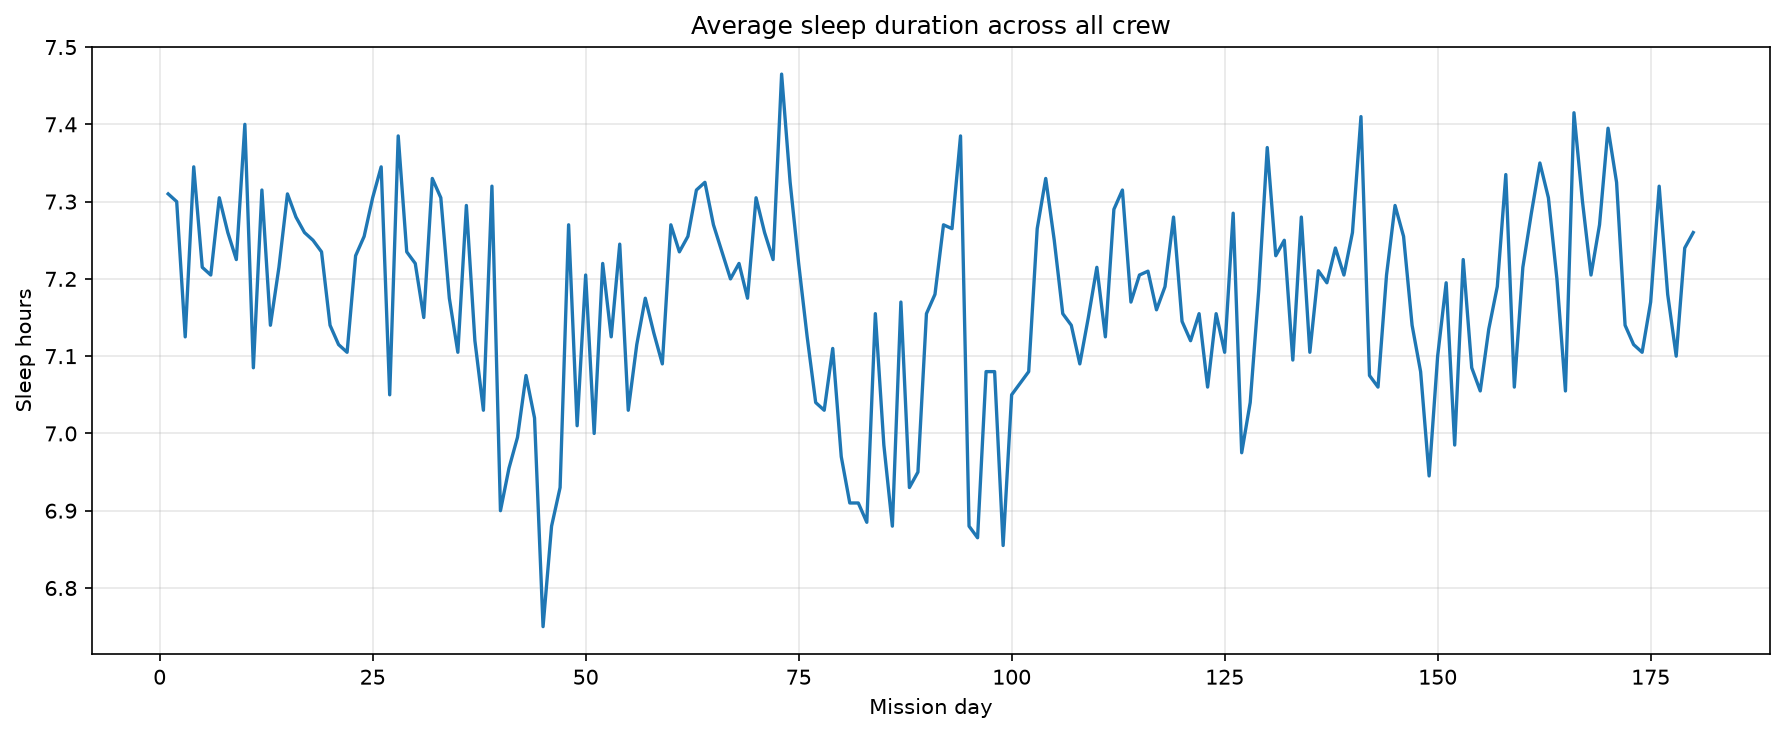

sleep_vs_baseline.png


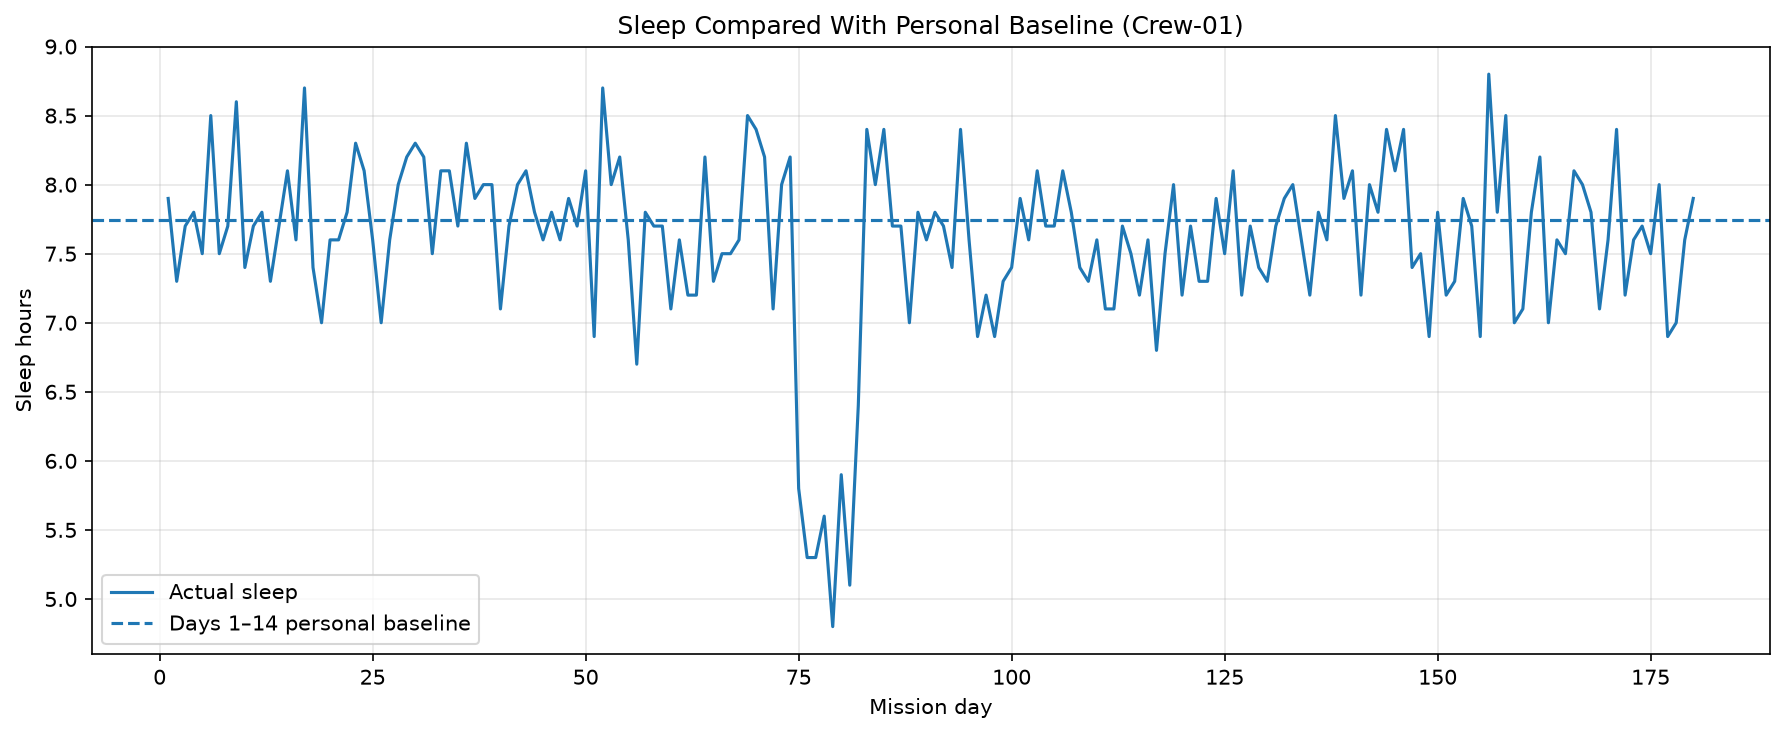

workload_crew01.png


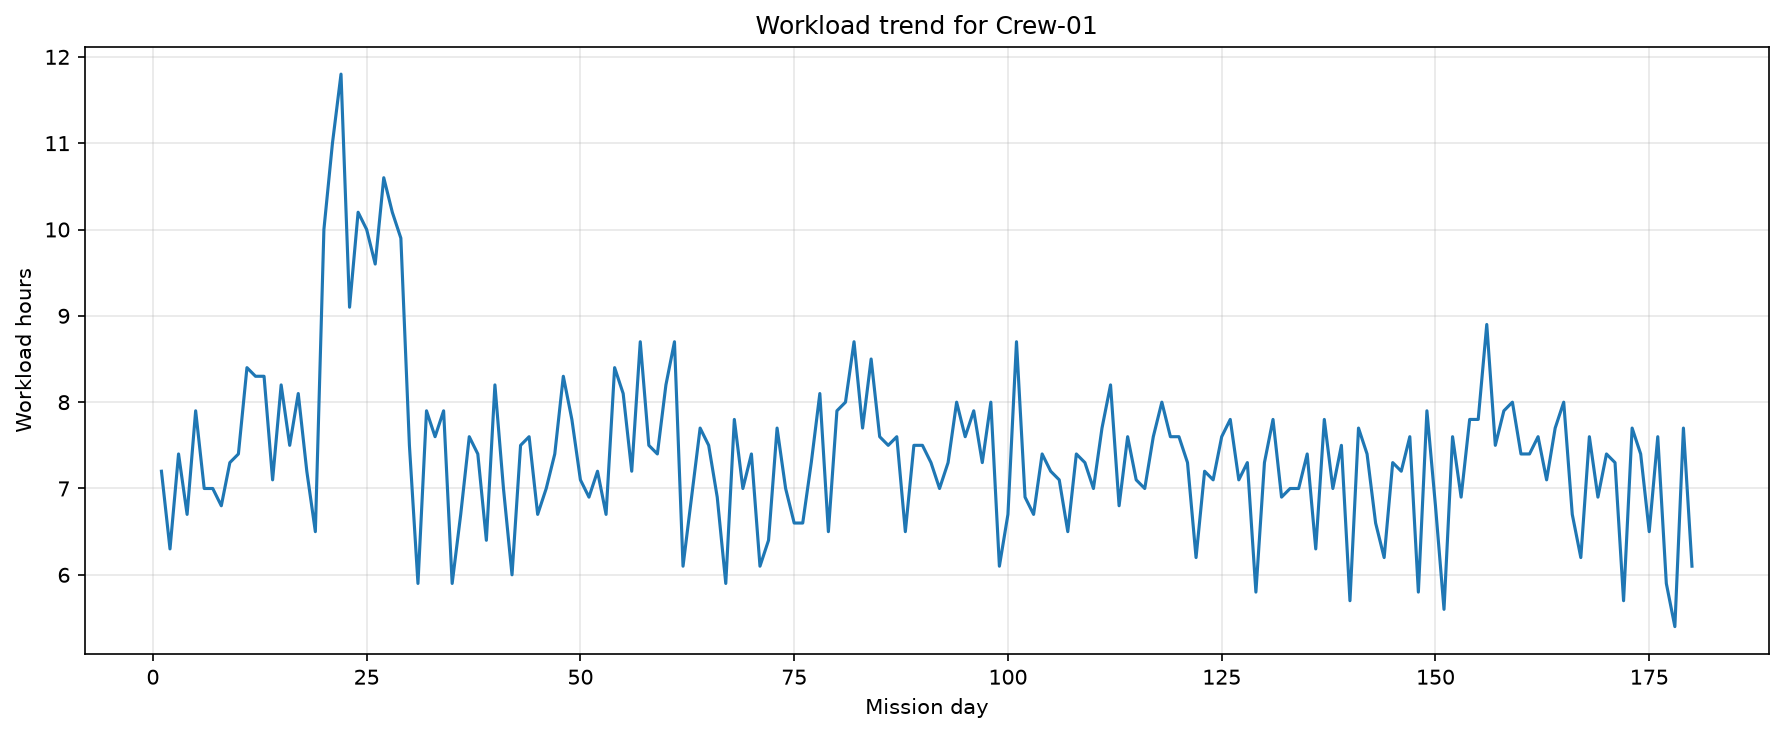

workload_hours_all_crew_daily_average.png


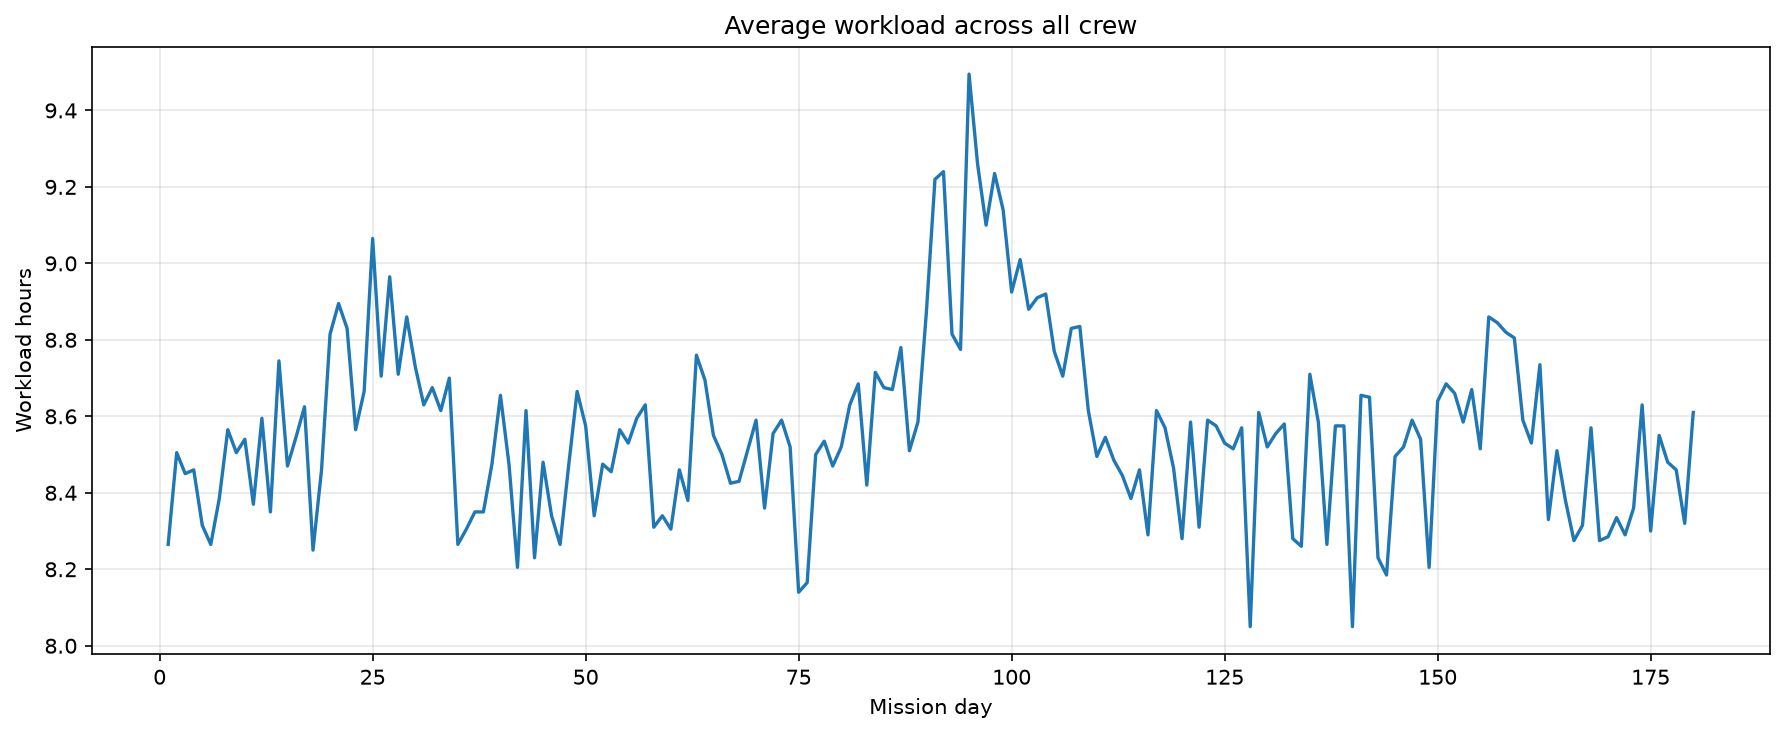

In [5]:
from IPython.display import display, Image

chart_folder = PROJECT_ROOT / "assets" / "analysis_charts"
chart_files = sorted(chart_folder.glob("*.png"))
print(f"Displaying {len(chart_files)} saved charts:")
for chart_file in chart_files:
    print(chart_file.name)
    display(Image(filename=str(chart_file)))


## 4. How to interpret the outputs

- `sleep_crew01.png`, `fatigue_crew01.png`, `workload_crew01.png`, and `reaction_time_crew01.png` show one crew member over time.
- The four `*_all_crew_daily_average.png` charts show average trends across crew members.
- `sleep_vs_baseline.png` compares Crew-01 sleep with the average from mission days 1–14.
- `correlation_heatmap.png` summarizes pairwise correlations.
- `possible_sleep_changes.csv` is an exploratory screen using whole-mission z-scores, not a real-time alert method.
- `docs/DATA_ANALYSIS.md` contains the full report; `docs/ML_HANDOFF.md` contains notes for the next team member.
